This notebook allows you to output visualizations for coarsening sequences and dataset samples in .pdf. Just run the following cells and fill in the informations in the cell at the bottom.

# Hypergraphs

### Class definitions

In [1]:
from abc import ABC, abstractmethod
from typing import Sequence

import numpy as np
import scipy as sp
from numpy.typing import NDArray
from scipy.sparse import coo_array, csr_array, eye, hstack, vstack, diags, csc_array, bmat

import hypernetx as hnx

real = np.floating | float


class Reduction(ABC):
    """Abstract class for graph reduction."""

    preserved_eig_size: int
    local_variation_cost: bool
    topological_cost_importance: real
    sqrt_partition_size: bool
    weighted_reduction: bool
    min_red_frac: real
    max_red_frac: real
    red_threshold: int
    rand_lambda: int

    def __init__(self, bipartite_adj, clique_adj, node_features, hyperedge_features, node_cluster_size=None, edge_cluster_size=None, lap=None, B=None, expansion_matrix=None, expansion_matrix_nodes=None, expansion_matrix_hyperedges=None, level=0):
        self.bipartite_adj = bipartite_adj
        self.clique_adj = clique_adj
        self.n = clique_adj.shape[0]
        
        if node_features is not None:
            self.node_features = node_features.astype(np.float64)
        else:
            self.node_features = None
        
        if node_cluster_size is not None:
            self.node_cluster_size = node_cluster_size
        else:
            self.node_cluster_size = np.ones(self.n)
        
        if hyperedge_features is not None:
            self.hyperedge_features = hyperedge_features.astype(np.float64)
        else:
            self.hyperedge_features = None
        
        if edge_cluster_size is not None:
            self.edge_cluster_size = edge_cluster_size
        else:
            self.edge_cluster_size = np.ones(bipartite_adj.shape[0] - self.n)
        
        self.node_degree = self.clique_adj.sum(0)
        self.lap = sp.sparse.diags(self.node_degree) - self.clique_adj if lap is None else lap
        if B is None:
            self.B = self.get_B0()
            self.A = self.B
        else:
            self.B = B
            self.A = self.get_A()

        self.expansion_matrix = expansion_matrix
        self.expansion_matrix_nodes = expansion_matrix_nodes
        self.expansion_matrix_hyperedges = expansion_matrix_hyperedges
        self.node_expansion = (
            np.ones(self.n, dtype=np.int32)
            if expansion_matrix is None
            else expansion_matrix.sum(0)[:self.n].astype(np.int32)
        )
        self.edge_expansion = (
            np.ones(self.bipartite_adj.shape[0] - self.n, dtype=np.int32)
            if expansion_matrix is None
            else expansion_matrix.sum(0)[self.n:].astype(np.int32)
        )
        self.level = level

    def get_reduced_hypergraph(self, rng=np.random.default_rng()):
        # Compute the coarsened clique representation
        C, collapsed_coarsened_incidence, edge_expansion_matrix = self.get_coarsening_matrix(rng)
        
        # P_inv = C.T with all non-zero entries set to 1
        P_inv = C.T.astype(bool).astype(C.dtype)

        if self.weighted_reduction:
            lap_reduced = P_inv.T @ self.lap @ P_inv
            adj_clique_reduced = -lap_reduced + sp.sparse.diags(lap_reduced.diagonal())
        else:
            lap_reduced = None
            adj_clique_reduced = (P_inv.T @ self.clique_adj @ P_inv).tocoo()
            # remove self-loops and edge weights
            row, col = adj_clique_reduced.row, adj_clique_reduced.col
            mask = row != col
            row, col = row[mask], col[mask]
            adj_clique_reduced = sp.sparse.coo_array(
                (np.ones(len(row), dtype=adj_clique_reduced.dtype), (row, col)),
                shape=adj_clique_reduced.shape,
            )
            
        # Reconstruct the bipartite adjacency matrix
        num_nodes, num_hyperedges = collapsed_coarsened_incidence.shape
        
        zero_nodes = csc_array((num_nodes, num_nodes))
        zero_hyperedges = csc_array((num_hyperedges, num_hyperedges))
        
        top = hstack([zero_nodes, collapsed_coarsened_incidence])
        bottom = hstack([collapsed_coarsened_incidence.T, zero_hyperedges])
        bipartite_adjacency = csc_array(vstack([top, bottom]))
        
        # Add the edge_expansion_matrix to the expansion matrix
        expansion_matrix = bmat([[P_inv, None], [None, edge_expansion_matrix]], format='coo')
        
        # Compute coarsened features and new cluster sizes
        node_cluster_size = np.atleast_1d(P_inv.T @ self.node_cluster_size)  # (k,)
        node_features = None
        if self.node_features is not None:
            # Reshape weighted features to 2D for sparse matrix multiplication
            original_shape = self.node_features.shape
            reshaped_features = self.node_features.reshape((original_shape[0], -1))  # (n, d1*d2*...)
            
            # Weight the features by the current node_cluster_size
            weighted_features = reshaped_features * self.node_cluster_size[:, None]
    
            # Sum features of the nodes inside each cluster
            summed_weighted_features = P_inv.T @ weighted_features  # (k, d1*d2*...)
            
            # Compute weighted average features
            node_features = summed_weighted_features / node_cluster_size[:, None]
    
            # Reshape back to the original feature dimensions
            summed_weighted_features = summed_weighted_features.reshape((P_inv.shape[1],) + original_shape[1:])  # (k, d1, d2, ...)
            
        edge_cluster_size = None
        hyperedge_features = None
        # TO DO
        
        cluster_id_nodes = P_inv.col[np.argsort(P_inv.row)]
        cluster_id_hyperedges = edge_expansion_matrix.col[np.argsort(edge_expansion_matrix.row)]
        
        return self.__class__(
            bipartite_adj=bipartite_adjacency,
            clique_adj=adj_clique_reduced,
            node_features=node_features,
            hyperedge_features=hyperedge_features,
            node_cluster_size=node_cluster_size,
            edge_cluster_size=edge_cluster_size,
            lap=lap_reduced,
            B=C @ self.B,
            expansion_matrix=expansion_matrix,
            expansion_matrix_nodes=P_inv,
            expansion_matrix_hyperedges=edge_expansion_matrix,
            level=self.level + 1,
        ), cluster_id_nodes, cluster_id_hyperedges

    def get_B0(self) -> NDArray:
        offset = 2 * np.max(self.node_degree)
        T = offset * sp.sparse.eye(self.n, format="csc") - self.lap
        lk, Uk = sp.sparse.linalg.eigsh(
            T, k=self.preserved_eig_size, which="LM", tol=1e-5
        )
        lk = (offset - lk)[::-1]
        Uk = Uk[:, ::-1]

        # compute L^-1/2
        mask = lk < 1e-5
        lk[mask] = 1
        lk_inv = 1 / np.sqrt(lk)
        lk_inv[mask] = 0
        return Uk * lk_inv[np.newaxis, :]  # = Uk @ np.diag(lk_inv)

    def get_A(self) -> NDArray:
        # A = B @ (B.T @ L @ B)^-1/2
        d, V = np.linalg.eig(self.B.T @ self.lap @ self.B)
        mask = d < 1e-8
        d[mask] = 1
        d_inv_sqrt = 1 / np.sqrt(d)
        d_inv_sqrt[mask] = 0
        return self.B @ np.diag(d_inv_sqrt) @ V
    
    def collapse_duplicate_edges(self, coarsened_incidence: csc_array, edge_expansion_matrix: csc_array):
        unique_columns = {}
        column_map = {}
        next_col_index = 0
        mergings = {}
    
        # Iterate through each column
        for col_index in range(coarsened_incidence.shape[1]):
            # Extract the column indices
            start, end = coarsened_incidence.indptr[col_index], coarsened_incidence.indptr[col_index + 1]
            col = tuple(coarsened_incidence.indices[start:end])
    
            if col in unique_columns:
                start_lifting, end_lifting = edge_expansion_matrix.indptr[col_index], edge_expansion_matrix.indptr[col_index+1]
                mergings[unique_columns[col]].extend(edge_expansion_matrix.indices[start_lifting:end_lifting])
            else:
                unique_columns[col] = next_col_index
                column_map[col_index] = next_col_index
                
                start_lifting, end_lifting = edge_expansion_matrix.indptr[col_index], edge_expansion_matrix.indptr[col_index+1]
                mergings[next_col_index] = list(edge_expansion_matrix.indices[start_lifting:end_lifting])
                next_col_index += 1
    
        # Construct the collapsed incidence matrix
        incidence_collapsed_rows = []
        incidence_collapsed_indptr = np.zeros(next_col_index+1, dtype=int)
        
        lifting_collapsed_rows = []
        lifting_collapsed_indptr = np.zeros(next_col_index+1, dtype=int)
        
        for col, idx in unique_columns.items():
            incidence_collapsed_rows.extend(col)
            incidence_collapsed_indptr[idx+1:] += len(col)
            
            lifting_collapsed_rows.extend(mergings[idx])
            lifting_collapsed_indptr[idx+1:] += len(mergings[idx])
        
        # Create the collapsed matrices
        collapsed_incidence_matrix = csc_array((np.ones(incidence_collapsed_indptr[-1], dtype=int), incidence_collapsed_rows, incidence_collapsed_indptr), shape=(coarsened_incidence.shape[0], next_col_index))
        collapsed_lifting_matrix = csc_array((np.ones(lifting_collapsed_indptr[-1], dtype=int), lifting_collapsed_rows, lifting_collapsed_indptr), shape=(edge_expansion_matrix.shape[0], next_col_index))
    
        return collapsed_incidence_matrix, collapsed_lifting_matrix
    

    def get_coarsening_matrix(self, rng):
        # get the contraction sets and their costs
        contraction_sets = self.get_contraction_sets()
        topological_costs = (
            np.apply_along_axis(self.get_topological_cost, 1, contraction_sets)
            if len(contraction_sets) > 0
            else np.array([])
        )
        
        if self.node_features is not None:
            features_costs = (
                np.apply_along_axis(self.get_features_cost, 1, contraction_sets)
                if len(contraction_sets) > 0
                else np.array([])
            )
            
            # Get maximum values ignoring infinities, handle empty array case
            finite_topological = topological_costs[~np.isinf(topological_costs)]
            finite_features = features_costs[~np.isinf(features_costs)]
            
            topological_max = np.max(finite_topological) if finite_topological.size > 0 else 1
            features_max = np.max(finite_features) if finite_features.size > 0 else 1
            
            # Normalize each cost, preserving the infinite values
            topological_costs /= max(1, topological_max)
            features_costs /= max(1, features_max)
            
            # Weight costs
            costs = self.topological_cost_importance * topological_costs + (1 - self.topological_cost_importance) * features_costs
        else:
            costs = topological_costs

        # compute reduction fraction
        if self.n <= self.red_threshold:
            reduction_fraction = self.max_red_frac
        else:
            reduction_fraction = rng.uniform(self.min_red_frac, self.max_red_frac)

        # get partitioning minimizing the cost in a randomized fashion
        perm = costs.argsort()
        contraction_sets = contraction_sets[perm]
        partitions = []
        marked = np.zeros(self.n, dtype=bool)
        
        incidence_matrix = csc_array(self.bipartite_adj [:self.n, self.n:])
        edge_expansion_matrix = eye(incidence_matrix.shape[1], format='csc')
        
        # As we dynamically reduce the incidence matrix, the indices in the
        # contraction_set do not correspond to those of the matrix
        index_map = np.arange(incidence_matrix.shape[0])
        
        for contraction_set in contraction_sets:
            if (
                not marked[contraction_set].any()
                and rng.uniform() >= self.rand_lambda  # randomize
            ):
                index_map_contraction_set = index_map[contraction_set]
                
                # Merge the nodes              
                row_map = np.arange(incidence_matrix.shape[0])
                for idx in index_map_contraction_set[1:]: row_map[idx:] -= 1
                row_map[index_map_contraction_set] = index_map_contraction_set[0] # Sum on the first contraction index
                
                new_indices = row_map[incidence_matrix.indices]
                
                new_indices = []
                new_indptr = np.zeros(incidence_matrix.shape[1]+1, dtype=int)
                
                for i in range(incidence_matrix.shape[1]):
                    start, end = incidence_matrix.indptr[i], incidence_matrix.indptr[i+1]
                    coarsened_indices = np.unique(row_map[incidence_matrix.indices[start:end]])
                    new_indices.extend(coarsened_indices)
                    new_indptr[i+1:] += len(coarsened_indices)
                
                coarsened_incidence = csc_array((np.ones(new_indptr[-1], dtype=int), new_indices, new_indptr), shape=(incidence_matrix.shape[0] - len(index_map_contraction_set)+1, incidence_matrix.shape[1]))
                
                # Then merge the hyperedges  
                collapsed_coarsened_incidence, new_edge_expansion_matrix = self.collapse_duplicate_edges(coarsened_incidence, edge_expansion_matrix)

                if new_edge_expansion_matrix.sum(0).max() <= 3:
                    incidence_matrix = collapsed_coarsened_incidence
                    edge_expansion_matrix = new_edge_expansion_matrix
                    partitions.append(contraction_set)
                    marked[contraction_set] = True
                    
                    # Update the index map
                    for idx in contraction_set[1:]:
                        index_map[idx:] -= 1
                            
                    if marked.sum() - len(partitions) >= reduction_fraction * self.n:
                        break

        # construct projection matrix
        P = eye(self.n, format="lil")
        mask = np.ones(self.n, dtype=bool)
        for partition in partitions:
            size = len(partition)
            size = np.sqrt(size) if self.sqrt_partition_size else size
            P[partition[0], partition] = 1 / size
            mask[partition[1:]] = False
        P = P[mask, :]
        return coo_array(P, dtype=np.float64), incidence_matrix, coo_array(edge_expansion_matrix, dtype=np.float64)


    @abstractmethod
    def get_contraction_sets(self) -> Sequence[NDArray]:
        pass

    def get_topological_cost(self, nodes: NDArray) -> real:
        if self.local_variation_cost:
            return self.get_local_variation_cost(nodes)
        else:
            return np.random.rand()

    def get_local_variation_cost(self, nodes: NDArray) -> real:
        """Compute the local variation cost for a set of nodes"""
        nc = len(nodes)
        if nc == 1:
            return np.inf

        ones = np.ones(nc)
        W = self.clique_adj[nodes, :][:, nodes]
        L = np.diag(2 * self.node_degree[nodes] - W @ ones) - W
        B = (np.eye(nc) - np.outer(ones, ones) / nc) @ self.A[nodes, :]
        
        return np.linalg.norm(B.T @ L @ B) / (nc - 1)
        
        
    def get_features_cost(self, nodes: NDArray) -> real:
        return self.get_squared_distance_cost(nodes)

    def get_squared_distance_cost(self, nodes: NDArray) -> real:
        """Compute the squared distance cost for a set of nodes with features """
        nc = len(nodes)
        if nc == 1:
            return np.inf

        return np.sum((self.node_features[nodes[0]] - self.node_features[nodes[1]])**2)


class NeighborhoodReduction(Reduction):
    """Graph reduction by contracting neighborhoods."""

    def get_contraction_sets(self) -> Sequence[NDArray]:
        """Returns neighborhood contraction sets"""
        adj_with_self_loops = self.clique_adj.copy().tolil()
        adj_with_self_loops.setdiag(1)
        return [np.sort(np.array(nbrs)) for nbrs in adj_with_self_loops.rows]


class EdgeReduction(Reduction):
    """Graph reduction by contracting edges.

    Class implements optimized routines for local variation cost computation.
    """

    def get_contraction_sets(self) -> Sequence[NDArray]:
        us, vs, _ = sp.sparse.find(sp.sparse.triu(self.clique_adj))
        return np.stack([us, vs], axis=1)

    def get_local_variation_cost(self, edge: NDArray) -> real:
        """Compute the local variation cost for an edge"""
        u, v = edge
        w = self.clique_adj[u, v]
        L = np.array(
            [[2 * self.node_degree[u] - w, -w], [-w, 2 * self.node_degree[v] - w]]
        )
        B = self.A[edge, :]
        
        if self.node_features is not None:
            distance_features = np.sum((self.node_features[u] - self.node_features[v])**2)
            
            return distance_features + np.linalg.norm(B.T @ L @ B)
        else:
            return np.linalg.norm(B.T @ L @ B)


class ReductionFactory:
    def getIncidenceMatrix(self, H) -> csr_array:
        rows = []
        col = []
        
        dic_nodes = {node : i for node, i in zip(H.nodes, range(len(list(H.nodes))))}
        dic_edges = {edge : i for edge, i in zip(H.edges, range(len(list(H.edges))))}
        
        for edge in H.edges:
            for node in H.edges[edge]:
                rows.append(dic_nodes[node])
                col.append(dic_edges[edge])
        
        coo_mat = coo_array((np.ones(len(rows)), (rows, col)), (len(list(H.nodes)), len(list(H.edges))))
        return csr_array(coo_mat)
        
    def getBipartiteAdj(self, incidence_matrix) -> csr_array:
        # Ensure the incidence matrix is in CSR format
        incidence_matrix = csr_array(incidence_matrix)
        
        # Number of nodes and hyperedges
        num_nodes, num_hyperedges = incidence_matrix.shape
        
        # Create zero matrices for the non-connected parts
        zero_nodes = csr_array((num_nodes, num_nodes))
        zero_hyperedges = csr_array((num_hyperedges, num_hyperedges))
        
        # Stack and concatenate the matrices to form the bipartite adjacency matrix
        top = hstack([zero_nodes, incidence_matrix])
        bottom = hstack([incidence_matrix.T, zero_hyperedges])
        bipartite_adjacency = vstack([top, bottom])
        
        return csr_array(bipartite_adjacency)

    def getCliqueAdj(self, incidence_matrix) -> csr_array:
        # Compute the diagonal matrix D_E
        hyperedge_degrees = np.array(incidence_matrix.sum(axis=0)).flatten()
        D_E_inv = diags(1 / hyperedge_degrees)
        
        # Compute the adjacency matrix of the weighted clique expansion
        clique_adjacency = incidence_matrix @ D_E_inv @ incidence_matrix.T
        
        # Subtract the diagonal
        diagonal = clique_adjacency.diagonal()
        diag_matrix = sp.sparse.diags(diagonal, offsets=0, shape=clique_adjacency.shape, format='csr')

        clique_adjacency = clique_adjacency - diag_matrix
        clique_adjacency.eliminate_zeros()

        return clique_adjacency
    
    
    def __init__(
        self,
        contraction_family,
        cost_type,
        topological_cost_importance,
        preserved_eig_size,
        sqrt_partition_size,
        weighted_reduction,
        min_red_frac,
        max_red_frac,
        red_threshold,
        rand_lambda,
    ):
        self.contraction_family = contraction_family
        self.cost_type = cost_type
        self.topological_cost_importance = topological_cost_importance
        self.preserved_eig_size = preserved_eig_size
        self.sqrt_partition_size = sqrt_partition_size
        self.weighted_reduction = weighted_reduction
        self.min_red_frac = min_red_frac
        self.max_red_frac = max_red_frac
        self.red_threshold = red_threshold
        self.rand_lambda = rand_lambda

    def __call__(self, H: hnx.Hypergraph) -> Reduction:
        if self.contraction_family == "neighborhoods":
            reduction = NeighborhoodReduction
        elif self.contraction_family == "edges":
            reduction = EdgeReduction
        else:
            raise ValueError("Unknown contraction family.")

        if self.cost_type == "local_variation":
            reduction.local_variation_cost = True
        elif self.cost_type == "random":
            reduction.local_variation_cost = False
        else:
            raise ValueError("Unknown reduction cost type.")
            
        reduction.topological_cost_importance = self.topological_cost_importance
            
        node_features = None
        hyperedge_features= None
        
        if H.nodes[next(iter(H.nodes))].feature is not None:
            node_features = np.array([H.nodes[i].feature for i in H.nodes])
        
        if H.edges[next(iter(H.edges))].feature is not None:
            hyperedge_features = np.array([H.edges[i].feature for i in H.edges])

        reduction.preserved_eig_size = self.preserved_eig_size
        reduction.sqrt_partition_size = self.sqrt_partition_size
        reduction.weighted_reduction = self.weighted_reduction
        reduction.min_red_frac = self.min_red_frac
        reduction.max_red_frac = self.max_red_frac
        reduction.red_threshold = self.red_threshold
        reduction.rand_lambda = self.rand_lambda
        
        incidence_matrix = self.getIncidenceMatrix(H)

        return reduction(self.getBipartiteAdj(incidence_matrix), self.getCliqueAdj(incidence_matrix), node_features, hyperedge_features)


In [2]:
from abc import ABC

import numpy as np
import scipy as sp
import torch as th
from torch.utils.data import IterableDataset
from torch_geometric.data import Data

import pickle
import sys

class RandRedDataset(IterableDataset, ABC):
    def __init__(self, hypergraphs, red_factory: ReductionFactory, spectrum_extractor):
        super().__init__()

        self.red_factory = red_factory
        self.hypergraphs = hypergraphs
        self.spectrum_extractor = spectrum_extractor

    def get_random_reduction_sequence(self, reduction_level_zero, rng):
        data = []
        red = reduction_level_zero
        red_next, _, _ = red.get_reduced_hypergraph(rng)
        
        while True:
            reduced_hypergraph, cluster_id_nodes_reduced, cluster_id_hyperedges_reduced = red_next.get_reduced_hypergraph(rng)
            
            node_type = np.zeros(red.bipartite_adj.shape[0])
            node_type[:red.n] = 1
            
            node_type_reduced = np.zeros(red_next.bipartite_adj.shape[0])
            node_type_reduced[:red_next.n] = 1
            
            diff_node_features = None
            diff_hyperedge_features = None
            if reduced_hypergraph.node_features is not None or reduced_hypergraph.hyperedge_features is not None:
                expansion_numbers = np.sum(reduced_hypergraph.expansion_matrix, axis=0).astype(np.int64)
            
                if reduced_hypergraph.node_features is not None:
                    diff_node_features = np.abs(reduced_hypergraph.node_features[cluster_id_nodes_reduced] - red_next.node_features)
                
                if reduced_hypergraph.hyperedge_features is not None:
                    raise Exception("implementer idx_perm_hyperedge")
                    edge_node_map = np.repeat(np.arange(reduced_hypergraph.expansion_matrix.shape[0] - reduced_hypergraph.n), expansion_numbers[reduced_hypergraph.n:])
                    
                    diff_hyperedge_features = np.abs(reduced_hypergraph.hyperedge_features[edge_node_map] - red_next.hyperedge_features)

            data.append(
                ReducedGraphData(
                    target_size=reduction_level_zero.n,
                    reduction_level=red.level,
                    adj=red.bipartite_adj.astype(bool).astype(np.float32),
                    node_type=node_type,
                    node_features=red.node_features if red.node_features is not None else None,
                    node_cluster_size=red.node_cluster_size,
                    hyperedge_features=red.hyperedge_features,
                    node_expansion=red.node_expansion,
                    edge_expansion=red.edge_expansion,
                    adj_reduced=red_next.bipartite_adj.astype(bool).astype(np.float32),
                    node_type_reduced=node_type_reduced,
                    node_features_reduced=red_next.node_features,
                    node_features_diff=diff_node_features,
                    node_cluster_size_reduced=red_next.node_cluster_size,
                    hyperedge_features_reduced=red_next.hyperedge_features,
                    hyperedge_features_diff=diff_hyperedge_features,
                    expansion_matrix=red_next.expansion_matrix,
                    expansion_matrix_nodes=red_next.expansion_matrix_nodes,
                    expansion_matrix_hyperedges=red_next.expansion_matrix_hyperedges,
                    spectral_features_reduced=self.spectrum_extractor(red_next.bipartite_adj)
                    if self.spectrum_extractor is not None
                    else None,
                )
            )
            
            if red.n <= 1:
                break
            
            red = red_next
            red_next = reduced_hypergraph
            
            
        """adjs = []
        features = []
        num_nodes = []
        
        for b in data:
            adjs.append(b.adj.to_dense().cpu().numpy())
            features.append(b.node_features.cpu().numpy())
            num_nodes.append(th.sum(b.node_type).item())
            
            data = {"adj" : adjs, "features":features, "num_nodes":num_nodes}
            
        with open('data.pkl', 'wb') as file:
            pickle.dump(data, file)
        sys.exit("Sequence finished.")"""

        return data


class FiniteRandRedDataset(RandRedDataset):
    def __init__(
        self, hypergraphs, red_factory: ReductionFactory, spectrum_extractor, num_red_seqs
    ):
        super().__init__(hypergraphs, red_factory, spectrum_extractor)
        self.num_red_seqs = num_red_seqs

        self.rng = np.random.default_rng(seed=0)
        self.hypergraphs_reduced_data = {i: [] for i in range(len(hypergraphs))}
        for i, hypergraph in enumerate(hypergraphs):
            red = red_factory(hypergraph)
            for _ in range(num_red_seqs):
                self.hypergraphs_reduced_data[i] += self.get_random_reduction_sequence(
                    red, self.rng
                )

    def __iter__(self):
        while True:
            i = self.rng.integers(len(self.hypergraphs))
            j = self.rng.integers(len(self.hypergraphs_reduced_data[i]))
            yield self.hypergraphs_reduced_data[i][j]

    @property
    def max_node_expansion(self):
        return max(
            [
                rgd.node_expansion.max().item()
                for seq in self.hypergraphs_reduced_data
                for rgd in seq
            ]
        )


class InfiniteRandRedDataset(RandRedDataset):
    def __iter__(self):
        reds = [self.red_factory(hypergraph) for hypergraph in self.hypergraphs]
        
        # get process id
        worker_info = th.utils.data.get_worker_info()
        worker_id = worker_info.id if worker_info is not None else 0
        rng = np.random.default_rng(worker_id)

        # initialize graph_reduced_data
        hypergraphs_reduced_data = {
            i: self.get_random_reduction_sequence(hypergraph, rng)
            for i, hypergraph in enumerate(reds)
        }

        # yield random reduced graph data
        while True:
            i = rng.integers(len(self.hypergraphs))
            if len(hypergraphs_reduced_data[i]) == 0:
                hypergraphs_reduced_data[i] = self.get_random_reduction_sequence(
                    reds[i], rng
                )
                rng.shuffle(hypergraphs_reduced_data[i])

            yield hypergraphs_reduced_data[i].pop()

    @property
    def max_node_expansion(self):
        raise NotImplementedError


class ReducedGraphData(Data):
    def __init__(self, **kwargs):
        if not kwargs:
            super().__init__()
            return

        super().__init__(x=th.zeros(kwargs["adj"].shape[0]))
        for key, value in kwargs.items():
            if value is None:
                continue
            elif isinstance(value, int):
                value = th.tensor(value).type(th.long)
            elif isinstance(value, np.ndarray):
                value = th.from_numpy(value).type(
                    th.float32 if np.issubdtype(value.dtype, np.floating) else th.long
                )
            elif isinstance(value, sp.sparse.sparray):
                value = SparseTensor.from_scipy(value).type(
                    th.float32 if np.issubdtype(value.dtype, np.floating) else th.long
                )
            else:
                raise ValueError(f"Unsupported type {type(value)} for key {key}")

            setattr(self, key, value)

    def __cat_dim__(self, key, value, *args, **kwargs):
        if isinstance(value, SparseTensor):
            return (0, 1)  # concatenate along diagonal
        return super().__cat_dim__(key, value, *args, **kwargs)


/projects/share/apps/python/3.13.7/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
def compute_coarsening_sequence(reduction_level_zero):
    rng=np.random.default_rng()
    
    adjs = []
    node_featuress = []
    node_expansions = []
    ns = []
    expansion_matrices = []
    
    red = reduction_level_zero
    red_next, _, _ = red.get_reduced_hypergraph(rng)
    
    while True:
        reduced_hypergraph, cluster_id_nodes_reduced, cluster_id_hyperedges_reduced = red_next.get_reduced_hypergraph(rng)
    
        node_type = np.zeros(red.bipartite_adj.shape[0])
        node_type[:red.n] = 1
    
        node_type_reduced = np.zeros(red_next.bipartite_adj.shape[0])
        node_type_reduced[:red_next.n] = 1
    
        diff_node_features = None
        diff_hyperedge_features = None
        if reduced_hypergraph.node_features is not None or reduced_hypergraph.hyperedge_features is not None:
            expansion_numbers = np.sum(reduced_hypergraph.expansion_matrix, axis=0).astype(np.int64)
    
            if reduced_hypergraph.node_features is not None:
                diff_node_features = np.abs(reduced_hypergraph.node_features[cluster_id_nodes_reduced] - red_next.node_features)
    
            if reduced_hypergraph.hyperedge_features is not None:
                raise Exception("implementer idx_perm_hyperedge")
                edge_node_map = np.repeat(np.arange(reduced_hypergraph.expansion_matrix.shape[0] - reduced_hypergraph.n), expansion_numbers[reduced_hypergraph.n:])
    
                diff_hyperedge_features = np.abs(reduced_hypergraph.hyperedge_features[edge_node_map] - red_next.hyperedge_features)
    
        adjs.append(red.bipartite_adj.astype(bool).astype(np.float32))
        node_featuress.append(red.node_features)
        node_expansions.append(red.expansion_matrix_nodes)
        expansion_matrices.append(red.expansion_matrix)
        ns.append(red.n)
        
        if red.n <= 1:
            break
    
        red = red_next
        red_next = reduced_hypergraph
    
    hypergraphs = []
    
    for i in range(len(adjs)):
        adj = adjs[i]
        n = ns[i]
        node_features = node_featuress[i]
    
        # remind that we have :
        # Adj_bipartite = ( 0  H)
        #                 (H^T 0)
        adj = adj.todense()
    
        if np.max(adj) > 0.:
            num_hyperedges = adj.shape[0] - n
    
            incidence_matrix = adj[:n, n:n + num_hyperedges]
    
            H = hnx.Hypergraph.from_incidence_matrix(incidence_matrix)
            hypergraphs.append(H)
        else:
            H = hnx.Hypergraph(np.ones((2,2)))
            hypergraphs.append(H)
    
        H.add_nodes_from([ (node, {"feature": node_features[i]}) for (i, node) in enumerate(H.nodes)])

    return hypergraphs

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from scipy.spatial import ConvexHull
from mpl_toolkits.mplot3d.art3d import Poly3DCollection, Line3DCollection
from rdkit import Chem
from rdkit.Chem import Draw

def visualize_hypergraphs(pred_hypergraphs, mode='hypergraph', n_rows=None, n_cols=None, output_filename=None, include_H=True):
    if not pred_hypergraphs:
        print("No hypergraphs to display.")
        return

    n_total = len(pred_hypergraphs)
    if n_rows is None or n_cols is None:
        n = int(min(5, np.ceil(np.sqrt(n_total))))
        n_rows, n_cols = min(n, int(np.ceil(n_total / n))), n

    fig = None
    axs = None

    if mode == 'hypergraph':
        fig, axs = plt.subplots(n_rows, n_cols, figsize=(4*n_rows, 4*n_cols))
        axs = axs.flatten() if isinstance(axs, np.ndarray) else [axs]

        for i in range(min(n_rows * n_cols, n_total)):
            ax = axs[i]
            H = pred_hypergraphs[i]

            G = nx.Graph()
            for edge in H.edges:
                nodes = list(H.edges[edge])
                for i1 in range(len(nodes)):
                    for i2 in range(i1 + 1, len(nodes)):
                        G.add_edge(nodes[i1], nodes[i2])

            pos = nx.spring_layout(G, k=1, scale=1, iterations=100)

            for edge in H.edges:
                nodes = list(H.edges[edge])
                if len(nodes) > 2:
                    points = np.array([pos[node] for node in nodes])
                    hull = ConvexHull(points)
                    hull_points = points[hull.vertices]
                    hull_color = np.random.random(3) * 0.5 + 0.5
                    ax.fill(hull_points[:, 0], hull_points[:, 1], color=hull_color, alpha=0.3)
                    for simplex in hull.simplices:
                        ax.plot(points[simplex, 0], points[simplex, 1], color='salmon', linewidth=2, alpha=0.7)
                elif len(nodes) == 2:
                    node1, node2 = nodes
                    ax.plot([pos[node1][0], pos[node2][0]], [pos[node1][1], pos[node2][1]],
                            color='salmon', linewidth=2, alpha=0.7)

            nx.draw_networkx_nodes(G, pos, ax=ax, node_size=200, node_color='skyblue', alpha=1, linewidths=1, edgecolors='black')
            ax.axis('off')

    elif mode == 'mesh':
        fig = plt.figure(figsize=(4*n_cols, 4*n_rows))
        axs = []
        for i in range(n_rows):
            for j in range(n_cols):
                index = i * n_cols + j
                if index >= n_total:
                    break
                ax = fig.add_subplot(n_rows, n_cols, index + 1, projection='3d')
                ax.set_axis_off()
                axs.append(ax)
                
        for i in range(min(n_rows * n_cols, n_total)):
            ax = axs[i]
            H = pred_hypergraphs[i]
            positions = {node: H.nodes[node].feature for node in H.nodes}
            pos_array = np.array(list(positions.values()))

            ax.scatter(pos_array[:, 0], pos_array[:, 1], pos_array[:, 2], c='b', s=20)

            face_collection = []
            line_collection = []
            for edge in H.edges:
                edge_nodes = list(H.edges[edge])
                if len(edge_nodes) > 2:
                    face = np.array([positions[node] for node in edge_nodes])
                    face_collection.append(face)
                elif len(edge_nodes) == 2:
                    line = np.array([positions[node] for node in edge_nodes])
                    line_collection.append(line)

            if face_collection:
                poly = Poly3DCollection(face_collection, alpha=0.25, facecolor='r', edgecolor='k')
                ax.add_collection3d(poly)
            if line_collection:
                lines = Line3DCollection(line_collection, colors='black', linewidths=2)
                ax.add_collection3d(lines)

            pos_min, pos_max = np.min(pos_array)*0.7, np.max(pos_array)*0.7
            ax.set_xlim(pos_min, pos_max)
            ax.set_ylim(pos_min, pos_max)
            ax.set_zlim(pos_min, pos_max)

    elif mode in ['molecule', 'molecule_implicit_H']:
        fig, axs = plt.subplots(n_rows, n_cols, figsize=(4*n_rows, 4*n_cols))
        axs = axs.flatten() if isinstance(axs, np.ndarray) else [axs]

        allowed_atom_types = [1, 6, 7, 8, 9, 5, 14, 15, 16, 17, 35, 53] if mode == 'molecule' else [6, 7, 8, 9, 5, 14, 15, 16, 17, 35, 53]
        atom_types_decode = {idx: atomic_num for idx, atomic_num in enumerate(allowed_atom_types)}
        bond_types = [Chem.rdchem.BondType.SINGLE, Chem.rdchem.BondType.DOUBLE,
                      Chem.rdchem.BondType.TRIPLE, Chem.rdchem.BondType.AROMATIC]

        for i in range(min(n_rows * n_cols, n_total)):
            ax = axs[i]
            H = pred_hypergraphs[i]

            mol = Chem.RWMol()
            node_to_atom = {}

            for node in H.nodes:
                one_hot = H.nodes[node].feature
                atom_type = atom_types_decode.get(np.argmax(one_hot))
                if atom_type is not None:
                    atom = Chem.Atom(atom_type)
                    if mode == 'molecule':
                        atom.SetNoImplicit(True)
                    atom_idx = mol.AddAtom(atom)
                    node_to_atom[node] = atom_idx

            for edge in H.edges:
                nodes = list(H.edges[edge])
                for i1 in range(len(nodes)):
                    for i2 in range(i1 + 1, len(nodes)):
                        u, v = nodes[i1], nodes[i2]
                        bond_type = np.argmax(H.edges[edge].feature)
                        if bond_type <= 3 and mol.GetBondBetweenAtoms(node_to_atom[u], node_to_atom[v]) is None:
                            mol.AddBond(node_to_atom[u], node_to_atom[v], bond_types[bond_type])

            img = Draw.MolToImage(mol, size=(500, 500))
            ax.imshow(img)
            ax.axis('off')

    else:
        raise ValueError(f"Unknown visualization mode: {mode}")

    fig.tight_layout()
    
    if output_filename:
        fig.savefig(output_filename, format='pdf', bbox_inches='tight')

    return fig

### Sequence generation

In [6]:
import pickle

with open('SODA_Hypergraph-Generation-Features/data/manifoldNetAirplane.pkl', 'rb') as file:
    data = pickle.load(file)

# If you want to compute a coarsening sequence
H = data["train"][0]

factory = ReductionFactory(
    'edges',
    'local_variation',
    0,
    8,
    True,
    True,
    0.1,
    0.3,
    16,
    0.,
)

reduction_level_zero = factory(H)

hypergraphs = compute_coarsening_sequence(reduction_level_zero)

# If you want to display samples
# hypergraphs = data["train"][0:4]

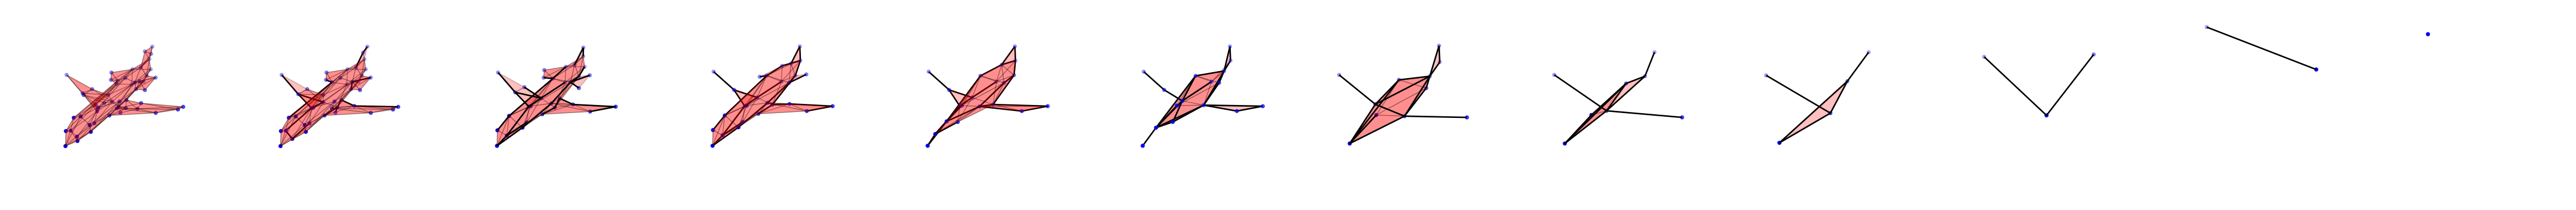

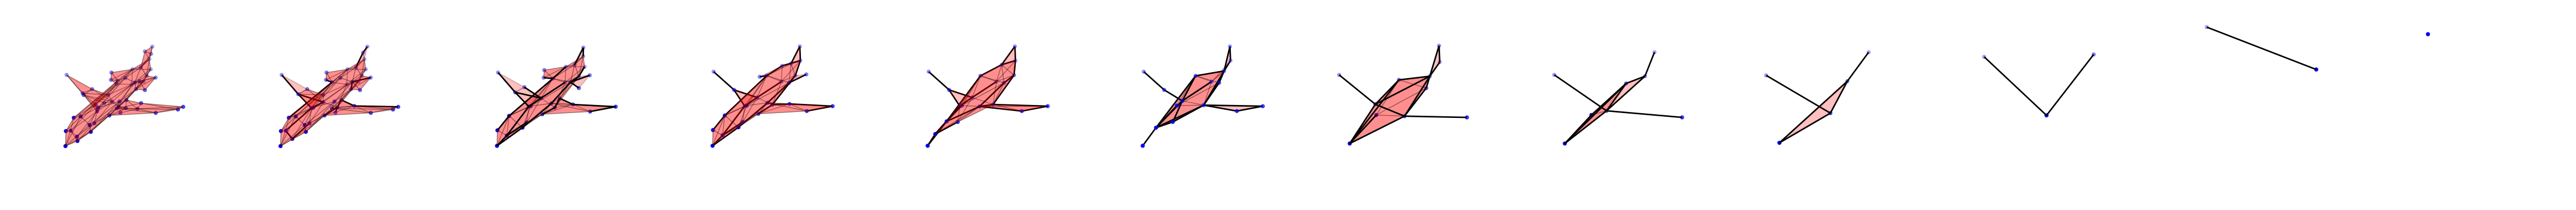

In [12]:
# You can change n_rows and n_cols to change the layout
# include_H refers to hydrogen atoms for molecules
visualize_hypergraphs(hypergraphs, mode='mesh', n_rows=1, n_cols=len(hypergraphs), output_filename="sequence_hypergraph.pdf", include_H=True)

## Graphs

### Class definitions

In [13]:
from abc import ABC, abstractmethod
from typing import Sequence

import networkx as nx

import numpy as np
import scipy as sp
from numpy.typing import NDArray
from scipy.sparse import coo_array, csr_array, eye

real = np.floating | float


class Reduction(ABC):
    """Abstract class for graph reduction."""

    preserved_eig_size: int
    local_variation_cost: bool
    sqrt_partition_size: bool
    weighted_reduction: bool
    min_red_frac: real
    max_red_frac: real
    red_threshold: int
    rand_lambda: int

    def __init__(self, adj, node_features, node_cluster_size=None, lap=None, B=None, expansion_matrix=None, level=0):
        self.adj = csr_array(adj, dtype=np.float64)
        self.n = adj.shape[0]
        self.node_degree = adj.sum(0)
        self.lap = sp.sparse.diags(self.node_degree) - adj if lap is None else lap
        if B is None:
            self.B = self.get_B0()
            self.A = self.B
        else:
            self.B = B
            self.A = self.get_A()

        self.expansion_matrix = expansion_matrix
        self.node_expansion = (
            np.ones(self.n, dtype=np.int32)
            if expansion_matrix is None
            else expansion_matrix.sum(0).astype(np.int32)
        )
        if node_features is not None:
            self.node_features = node_features.astype(np.float64)
        else:
            self.node_features = None
        
        if node_cluster_size is not None:
            self.node_cluster_size = node_cluster_size
        else:
            self.node_cluster_size = np.ones(self.n)
        self.level = level

    def get_reduced_graph(self, rng=np.random.default_rng()):
        C = self.get_coarsening_matrix(rng)
        # P_inv = C.T with all non-zero entries set to 1
        P_inv = C.T.astype(bool).astype(C.dtype)

        if self.weighted_reduction:
            lap_reduced = P_inv.T @ self.lap @ P_inv
            adj_reduced = -lap_reduced + sp.sparse.diags(lap_reduced.diagonal())
        else:
            lap_reduced = None
            adj_reduced = (P_inv.T @ self.adj @ P_inv).tocoo()
            # remove self-loops and edge weights
            row, col = adj_reduced.row, adj_reduced.col
            mask = row != col
            row, col = row[mask], col[mask]
            adj_reduced = sp.sparse.coo_array(
                (np.ones(len(row), dtype=adj_reduced.dtype), (row, col)),
                shape=adj_reduced.shape,
            )
            
        # Compute coarsened features and new cluster sizes
        node_cluster_size = np.atleast_1d(P_inv.T @ self.node_cluster_size)  # (k,)
        
        node_features = None
        if self.node_features is not None:
            # Reshape weighted features to 2D for sparse matrix multiplication
            original_shape = self.node_features.shape
            reshaped_features = self.node_features.reshape((original_shape[0], -1))  # (n, d1*d2*...)
            
            # Weight the features by the current node_cluster_size
            weighted_features = reshaped_features * self.node_cluster_size[:, None]
    
            # Sum features of the nodes inside each cluster
            summed_weighted_features = P_inv.T @ weighted_features  # (k, d1*d2*...)
            
            # Compute weighted average features
            node_features = summed_weighted_features / node_cluster_size[:, None]
    
            # Reshape back to the original feature dimensions
            summed_weighted_features = summed_weighted_features.reshape((P_inv.shape[1],) + original_shape[1:])  # (k, d1, d2, ...)

        return self.__class__(
            adj=adj_reduced,
            node_features=node_features,
            node_cluster_size=node_cluster_size,
            lap=lap_reduced,
            B=C @ self.B,
            expansion_matrix=P_inv,
            level=self.level + 1,
        )

    def get_B0(self) -> NDArray:
        offset = 2 * np.max(self.node_degree)
        T = offset * sp.sparse.eye(self.n, format="csc") - self.lap
        lk, Uk = sp.sparse.linalg.eigsh(
            T, k=self.preserved_eig_size, which="LM", tol=1e-5
        )
        lk = (offset - lk)[::-1]
        Uk = Uk[:, ::-1]

        # compute L^-1/2
        mask = lk < 1e-5
        lk[mask] = 1
        lk_inv = 1 / np.sqrt(lk)
        lk_inv[mask] = 0
        return Uk * lk_inv[np.newaxis, :]  # = Uk @ np.diag(lk_inv)

    def get_A(self) -> NDArray:
        # A = B @ (B.T @ L @ B)^-1/2
        d, V = np.linalg.eig(self.B.T @ self.lap @ self.B)
        mask = d < 1e-8
        d[mask] = 1
        d_inv_sqrt = 1 / np.sqrt(d)
        d_inv_sqrt[mask] = 0
        return self.B @ np.diag(d_inv_sqrt) @ V

    def get_coarsening_matrix(self, rng) -> coo_array:
        # get the contraction sets and their costs
        contraction_sets = self.get_contraction_sets()
        costs = (
            np.apply_along_axis(self.get_cost, 1, contraction_sets)
            if len(contraction_sets) > 0
            else np.array([])
        )

        # compute reduction fraction
        if self.n <= self.red_threshold:
            reduction_fraction = self.max_red_frac
        else:
            reduction_fraction = rng.uniform(self.min_red_frac, self.max_red_frac)

        # get partitioning minimizing the cost in a randomized fashion
        perm = costs.argsort()
        contraction_sets = contraction_sets[perm]
        partitions = []
        marked = np.zeros(self.n, dtype=bool)
        for contraction_set in contraction_sets:
            if (
                not marked[contraction_set].any()
                and rng.uniform() >= self.rand_lambda  # randomize
            ):
                partitions.append(contraction_set)
                marked[contraction_set] = True
                if marked.sum() - len(partitions) >= reduction_fraction * self.n:
                    break

        # construct projection matrix
        P = eye(self.n, format="lil")
        mask = np.ones(self.n, dtype=bool)
        for partition in partitions:
            size = len(partition)
            size = np.sqrt(size) if self.sqrt_partition_size else size
            P[partition[0], partition] = 1 / size
            mask[partition[1:]] = False
        P = P[mask, :]
        return coo_array(P, dtype=np.float64)

    @abstractmethod
    def get_contraction_sets(self) -> Sequence[NDArray]:
        pass

    def get_cost(self, nodes: NDArray) -> real:
        if self.local_variation_cost:
            return self.get_local_variation_cost(nodes)
        else:
            return np.random.rand()

    def get_local_variation_cost(self, nodes: NDArray) -> real:
        """Compute the local variation cost for a set of nodes"""
        nc = len(nodes)
        if nc == 1:
            return np.inf

        ones = np.ones(nc)
        W = self.adj[nodes, :][:, nodes]
        L = np.diag(2 * self.node_degree[nodes] - W @ ones) - W
        B = (np.eye(nc) - np.outer(ones, ones) / nc) @ self.A[nodes, :]
        return np.linalg.norm(B.T @ L @ B) / (nc - 1)


class NeighborhoodReduction(Reduction):
    """Graph reduction by contracting neighborhoods."""

    def get_contraction_sets(self) -> Sequence[NDArray]:
        """Returns neighborhood contraction sets"""
        adj_with_self_loops = self.adj.copy().tolil()
        adj_with_self_loops.setdiag(1)
        return [np.array(nbrs) for nbrs in adj_with_self_loops.rows]


class EdgeReduction(Reduction):
    """Graph reduction by contracting edges.

    Class implements optimized routines for local variation cost computation.
    """

    def get_contraction_sets(self) -> Sequence[NDArray]:
        us, vs, _ = sp.sparse.find(sp.sparse.triu(self.adj))
        return np.stack([us, vs], axis=1)

    def get_local_variation_cost(self, edge: NDArray) -> real:
        """Compute the local variation cost for an edge"""
        u, v = edge
        w = self.adj[u, v]
        L = np.array(
            [[2 * self.node_degree[u] - w, -w], [-w, 2 * self.node_degree[v] - w]]
        )
        B = self.A[edge, :]
        return np.linalg.norm(B.T @ L @ B)


class ReductionFactory:
    def __init__(
        self,
        contraction_family,
        cost_type,
        preserved_eig_size,
        sqrt_partition_size,
        weighted_reduction,
        min_red_frac,
        max_red_frac,
        red_threshold,
        rand_lambda,
        extract_node_features=0
    ):
        self.contraction_family = contraction_family
        self.cost_type = cost_type
        self.preserved_eig_size = preserved_eig_size
        self.sqrt_partition_size = sqrt_partition_size
        self.weighted_reduction = weighted_reduction
        self.min_red_frac = min_red_frac
        self.max_red_frac = max_red_frac
        self.red_threshold = red_threshold
        self.rand_lambda = rand_lambda
        self.extract_node_features = extract_node_features

    def __call__(self, G: nx.Graph) -> Reduction:
        if self.contraction_family == "neighborhoods":
            reduction = NeighborhoodReduction
        elif self.contraction_family == "edges":
            reduction = EdgeReduction
        else:
            raise ValueError("Unknown contraction family.")

        if self.cost_type == "local_variation":
            reduction.local_variation_cost = True
        elif self.cost_type == "random":
            reduction.local_variation_cost = False
        else:
            raise ValueError("Unknown reduction cost type.")

        reduction.preserved_eig_size = self.preserved_eig_size
        reduction.sqrt_partition_size = self.sqrt_partition_size
        reduction.weighted_reduction = self.weighted_reduction
        reduction.min_red_frac = self.min_red_frac
        reduction.max_red_frac = self.max_red_frac
        reduction.red_threshold = self.red_threshold
        reduction.rand_lambda = self.rand_lambda
        
        adj = nx.to_scipy_sparse_array(G, dtype=np.float64)
        
        node_features = None
        if self.extract_node_features:
            num_nodes = adj.shape[0]
            feat_dim = len(G.nodes[next(iter(G.nodes))]["feature"])
            node_features = np.empty((num_nodes, feat_dim), dtype=np.float32)

            for i, node in enumerate(G.nodes):
                node_features[i] = G.nodes[node]["feature"]

        return reduction(adj, node_features)

In [14]:
from abc import ABC

import numpy as np
import scipy as sp
import torch as th
from torch.utils.data import IterableDataset
from torch_geometric.data import Data
from torch_geometric.typing import SparseTensor

class RandRedDataset(IterableDataset, ABC):
    def __init__(self, graphs, red_factory: ReductionFactory, spectrum_extractor):
        super().__init__()

        self.red_factory = red_factory
        self.graphs = graphs
        self.spectrum_extractor = spectrum_extractor

    def get_random_reduction_sequence(self, reduction_level_zero, rng):
        data = []
        graph = reduction_level_zero
        while True:
            reduced_graph = graph.get_reduced_graph(rng)
            data.append(
                ReducedGraphData(
                    target_size=reduction_level_zero.n,
                    reduction_level=graph.level,
                    adj=graph.adj.astype(bool).astype(np.float32),
                    node_expansion=graph.node_expansion,
                    node_features=graph.node_features,
                    node_cluster_size=graph.node_cluster_size,
                    adj_reduced=reduced_graph.adj.astype(bool).astype(np.float32),
                    node_features_reduced=reduced_graph.node_features if graph.n != 1 or reduced_graph.node_features is None else np.zeros_like(reduced_graph.node_features),
                    node_cluster_size_reduced=reduced_graph.node_cluster_size,
                    expansion_matrix=reduced_graph.expansion_matrix,
                    spectral_features_reduced=self.spectrum_extractor(reduced_graph.adj)
                    if self.spectrum_extractor is not None
                    else None,
                )
            )
            if graph.n <= 1:
                break
            graph = reduced_graph

        return data


class FiniteRandRedDataset(RandRedDataset):
    def __init__(
        self, graphs, red_factory: ReductionFactory, spectrum_extractor, num_red_seqs
    ):
        super().__init__(graphs, red_factory, spectrum_extractor)
        self.num_red_seqs = num_red_seqs

        self.rng = np.random.default_rng(seed=0)
        self.graph_reduced_data = {i: [] for i in range(len(graphs))}
        for i, graph in enumerate(graphs):
            graph = red_factory(graph)
            for _ in range(num_red_seqs):
                self.graph_reduced_data[i] += self.get_random_reduction_sequence(
                    graph, self.rng
                )

    def __iter__(self):
        while True:
            i = self.rng.integers(len(self.adjs))
            j = self.rng.integers(len(self.graph_reduced_data[i]))
            yield self.graph_reduced_data[i][j]

    @property
    def max_node_expansion(self):
        return max(
            [
                rgd.node_expansion.max().item()
                for seq in self.graph_reduced_data
                for rgd in seq
            ]
        )


class InfiniteRandRedDataset(RandRedDataset):
    def __iter__(self):
        graphs = [self.red_factory(graph) for graph in self.graphs]

        # get process id
        worker_info = th.utils.data.get_worker_info()
        worker_id = worker_info.id if worker_info is not None else 0
        rng = np.random.default_rng(worker_id)

        # initialize graph_reduced_data
        graph_reduced_data = {
            i: []
            for i, graph in enumerate(graphs)
        }

        # yield random reduced graph data
        while True:
            i = rng.integers(len(graphs))
            if len(graph_reduced_data[i]) == 0:
                graph_reduced_data[i] = self.get_random_reduction_sequence(
                    graphs[i], rng
                )
                rng.shuffle(graph_reduced_data[i])

            yield graph_reduced_data[i].pop()

    @property
    def max_node_expansion(self):
        raise NotImplementedError


class ReducedGraphData(Data):
    def __init__(self, **kwargs):
        if not kwargs:
            super().__init__()
            return

        super().__init__(x=th.zeros(kwargs["adj"].shape[0]))
        for key, value in kwargs.items():
            if value is None:
                continue
            elif isinstance(value, int):
                value = th.tensor(value).type(th.long)
            elif isinstance(value, np.ndarray):
                value = th.from_numpy(value).type(
                    th.float32 if np.issubdtype(value.dtype, np.floating) else th.long
                )
            elif isinstance(value, sp.sparse.sparray):
                value = SparseTensor.from_scipy(value).type(
                    th.float32 if np.issubdtype(value.dtype, np.floating) else th.long
                )
            else:
                raise ValueError(f"Unsupported type {type(value)} for key {key}")

            setattr(self, key, value)

    def __cat_dim__(self, key, value, *args, **kwargs):
        if isinstance(value, SparseTensor):
            return (0, 1)  # concatenate along diagonal
        return super().__cat_dim__(key, value, *args, **kwargs)

In [15]:
def compute_coarsening_sequence(reduction_level_zero):
    rng=np.random.default_rng()
    
    adjs = []
    node_featuress = []
    node_expansions = []
    ns = []
    expansion_matrices = []
    
    red = reduction_level_zero
    red_next = red.get_reduced_graph(rng)
    
    while True:
        reduced_graph = red_next.get_reduced_graph(rng)
        if reduced_graph.node_features is not None:
            expansion_numbers = np.sum(reduced_graph.expansion_matrix, axis=0).astype(np.int64)
    
        adjs.append(red.adj.astype(bool).astype(np.float32))
        node_featuress.append(red.node_features)
        node_expansions.append(red.expansion_matrix)
        expansion_matrices.append(red.expansion_matrix)
        ns.append(red.n)
    
        if red.n <= 1:
            break
    
        red = red_next
        red_next = reduced_graph
    
    graphs = []
    
    for i in range(len(adjs)):
        adj = adjs[i]
        n = ns[i]
        node_features = node_featuress[i]
        
        # Create NetworkX graph from CSR matrix
        G = nx.from_scipy_sparse_array(adj)
        
        if node_features is not None:
            node_features = node_features
            G.add_nodes_from([ (node, {"feature": node_features[i]}) for (i, node) in enumerate(G.nodes)])
    
        graphs.append(G)

    return graphs

In [16]:
def visualize_graphs(pred_graphs, mode='graph', n_rows=None, n_cols=None, output_filename=None):
    if not pred_graphs:
        print("No graphs to display.")
        return

    n_total = len(pred_graphs)
    if n_rows is None or n_cols is None:
        n = int(min(5, np.ceil(np.sqrt(n_total))))
        n_rows, n_cols = min(n, int(np.ceil(n_total / n))), n

    fig = None
    axs = None

    if mode == 'graph':
        fig, axs = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 4*n_rows))
        axs = axs.flatten() if isinstance(axs, np.ndarray) else [axs]

        for i in range(min(n_rows * n_cols, n_total)):
            ax = axs[i]
            G = pred_graphs[i]
            pos = nx.spring_layout(G, seed=0)

            nx.draw_networkx_nodes(
                G,
                pos,
                ax=ax,
                node_size=200,
                node_color='skyblue',
                edgecolors='black',
                linewidths=1,
                alpha=1
            )
        
            nx.draw_networkx_edges(
                G,
                pos,
                ax=ax,
                width=2,
                edge_color='salmon',
                alpha=0.7
            )
            ax.axis('off')

    elif mode == 'point_cloud':
        fig = plt.figure(figsize=(4*n_cols, 4*n_rows))
        axs = []
        for i in range(n_rows):
            for j in range(n_cols):
                index = i * n_cols + j
                if index >= n_total:
                    break
                ax = fig.add_subplot(n_rows, n_cols, index + 1, projection='3d')
                ax.set_axis_off()
                axs.append(ax)

        for i in range(min(n_rows * n_cols, n_total)):
            ax = axs[i]
            G = pred_graphs[i]
                
            # Extract node positions from the 'feature' attribute
            positions = {node: G.nodes[node]["feature"] for node in G.nodes}
        
            # Convert positions to a numpy array for plotting
            pos_array = np.array(list(positions.values()))
        
            xs, ys, zs = pos_array[:,0], pos_array[:,1], pos_array[:,2]
            
            # color points by Z for depth effect
            colors = (zs - zs.min()) / (zs.max() - zs.min() + 1e-8)
            ax.scatter(xs, ys, zs, s=20, c=colors, cmap='viridis', alpha=0.8)
        
            # Set axis limits
            pos_min = np.min(pos_array) * 0.8
            pos_max = np.max(pos_array) * 0.8
            ax.set_xlim(pos_min, pos_max)
            ax.set_ylim(pos_min, pos_max)
            ax.set_zlim(pos_min, pos_max)
            
    fig.tight_layout()
    
    if output_filename:
        fig.savefig(output_filename, format='pdf', bbox_inches='tight')

    return fig

### Sequence generation

In [17]:
import pickle

with open('graph-generation-features/data/pointCloudBench.pkl', 'rb') as file:
    data = pickle.load(file)

G = data["train"][26]

# If you want to compute a coarsening sequence
factory = ReductionFactory(
    'edges',
    'local_variation',
    8,
    True,
    True,
    0.5,
    0.5,
    16,
    0.,
    True
)

reduction_level_zero = factory(G)

graphs = compute_coarsening_sequence(reduction_level_zero)

# If you want to display samples
# hypergraphs = data["train"][0:4]

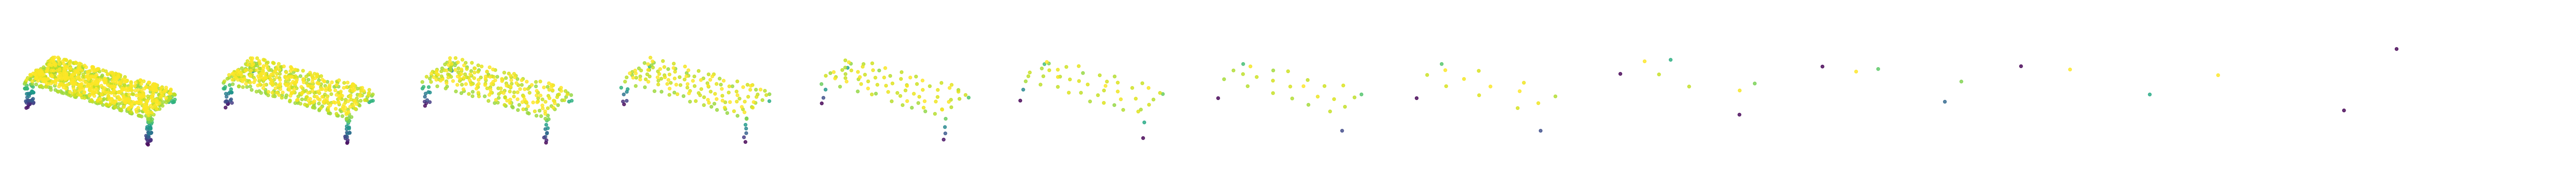

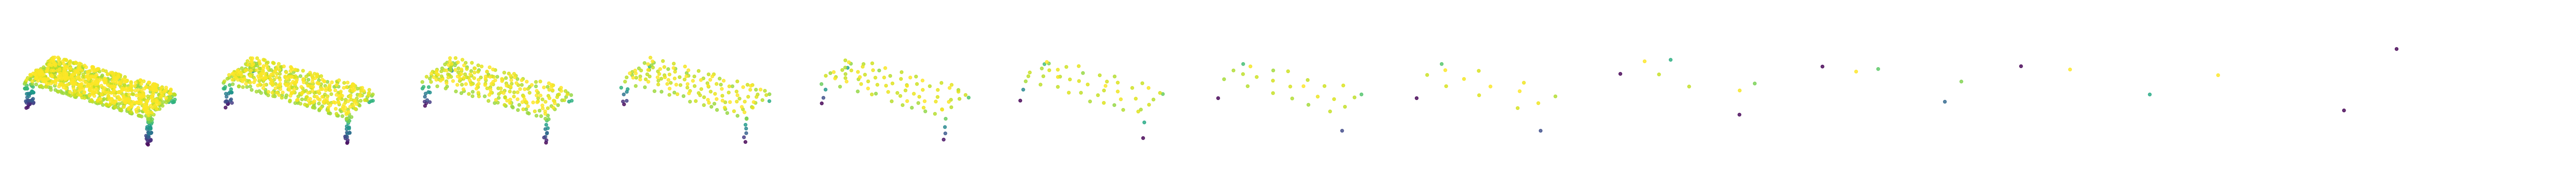

In [18]:
# You can change n_rows and n_cols to change the layout
visualize_graphs(graphs, mode='point_cloud', n_rows=1, n_cols=len(graphs), output_filename="sequence_graph_bench3.pdf")